# 트랜스포머 실습 1: 셀프 어텐션 직접 계산하기

이론 시간의 예제 그대로: **baseball bat** vs **cave bat**, 같은 bat이 문맥에 따라 어떻게 달라지나

| 순서 | 내용 | 시간 |
|---|---|---|
| 1 | 손계산 확인: Q·K·V → 점수 → softmax → 가중합 | 5분 |
| 2 | 문맥에 따라 bat 벡터가 달라짐 | 5분 |
| 3 | 순서를 바꾸면? → 위치 인코딩 | 5분 |
| 4 | `nn.MultiheadAttention`으로 같은 계산 | 5분 |
| 5 | 학습: bat → 배트? 박쥐? 어텐션 맵 보기 | 5분 |
| 6 | 마스크: 미래 가리기 | 5분 |
| 7 | 문제 (코드를 직접 고쳐 보기) | 남는 시간·과제 |

In [1]:
import math
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")  # NVIDIA GPU
    if torch.backends.mps.is_available():
        return torch.device("mps")  # Apple 실리콘 GPU
    return torch.device("cpu")


device = get_device()
print(device)


torch.manual_seed(0)
torch.set_printoptions(precision=2, sci_mode=False)

cuda


## 1. 손계산 확인: baseball bat
단어 벡터(임베딩)는 숫자 2개로 단순하게 정함
- baseball = [1, 0] (야구 성질), cave = [0, 1] (동굴 성질), bat = [1, 1] (둘 다 가능)
- 예제는 단순하게 $W_Q = W_K = W_V = I$ (단위 행렬). 실제 모델에서는 학습으로 찾는 값

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

In [38]:
device = get_device()

emb = {"baseball": [1.0, 0.0], "cave": [0.0, 1.0], "bat": [1.0, 1.0]}

W_Q = torch.eye(2)      # Query: 내가 찾는 것
W_K = torch.eye(2)      # Key:   나를 찾게 해 주는 이름표
W_V = torch.eye(2)      # Value: 실제로 전달할 내용

W_Q = W_Q.to(device)
W_K = W_K.to(device)
W_V = W_V.to(device)

def self_attention(X, W_Q, W_K, W_V, mask=None, show=True):
    Q, K, V = X @ W_Q, X @ W_K, X @ W_V
    X = X.to(device)  # Ensure input is on the same device as the weights

    d_k = K.shape[-1]
    S = Q @ K.T / math.sqrt(d_k)                      # 점수: 단어 쌍마다 얼마나 관련 있나
    if mask is not None:
        mask = mask.to(device)  # Ensure mask is on the same device as the scores
        S = S.masked_fill(mask, float("-inf"))        # 가린 칸은 -무한대 → softmax 후 0
    A = torch.softmax(S, dim=-1)                      # 행마다 합이 1인 가중치
    O = A @ V                                         # 가중치로 V를 섞음
    if show:
        S = S.to("cpu")  # Move score matrix to CPU for visualization
        A = A.to("cpu")  # Move attention matrix to CPU for visualization
        O = O.to("cpu")  # Move output to CPU for visualization

        print("점수 S = QKᵀ/√d_k\n", S)
        print("어텐션 가중치 A = softmax(S)\n", A)
        print("출력 O = A·V\n", O)
    return A, O

sent = ["baseball", "bat"]
X = torch.tensor([emb[w] for w in sent]).to(device)
print("입력 X\n", X)
A, O = self_attention(X, W_Q.to(device), W_K.to(device), W_V.to(device))


입력 X
 tensor([[1., 0.],
        [1., 1.]], device='cuda:0')
점수 S = QKᵀ/√d_k
 tensor([[0.71, 0.71],
        [0.71, 1.41]])
어텐션 가중치 A = softmax(S)
 tensor([[0.50, 0.50],
        [0.33, 0.67]])
출력 O = A·V
 tensor([[1.00, 0.50],
        [1.00, 0.67]])


- bat 행: 점수 [0.71, 1.41] → softmax [0.33, 0.67] → 출력 = 0.33×baseball + 0.67×bat = **[1.00, 0.67]**
- 슬라이드 손계산과 같은 숫자인지 확인

## 2. 문맥에 따라 bat 벡터가 달라짐
같은 bat인데 옆 단어가 cave면?

In [3]:
device = get_device()

for sent in [["baseball", "bat"], ["cave", "bat"]]:
    X = torch.tensor([emb[w] for w in sent]).to(device)
    A, O = self_attention(X, W_Q.to(device), W_K.to(device), W_V.to(device), show=False)
    r = lambda v: [round(x, 2) for x in v.tolist()]
    print(f"{' '.join(sent):13s} → bat 가중치 {r(A[1])}  bat 출력 {r(O[1])}")
    

baseball bat  → bat 가중치 [0.33, 0.67]  bat 출력 [1.0, 0.67]
cave bat      → bat 가중치 [0.33, 0.67]  bat 출력 [0.67, 1.0]


- 입력 bat은 둘 다 [1, 1]인데, 어텐션을 지나면 **[1.00, 0.67] (야구 쪽)** vs **[0.67, 1.00] (동굴 쪽)**
- 다음 층(분류기)은 이 벡터로 배트/박쥐를 구분할 수 있음
- RNN은 기억 h를 한 칸씩 넘겨서 문맥을 전달, 어텐션은 **다른 단어를 직접 보고 섞어서** 전달

## 3. 순서를 바꾸면? → 위치 인코딩
어텐션은 모든 단어를 한꺼번에 봄 → 순서를 모름. `[bat, baseball]`로 바꿔 보기

In [5]:
device = get_device()

for sent in [["baseball", "bat"], ["bat", "baseball"]]:
    X = torch.tensor([emb[w] for w in sent]).to(device)
    A, O = self_attention(X, W_Q.to(device), W_K.to(device), W_V.to(device), show=False)
    i = sent.index("bat")
    print(f"{' '.join(sent):13s} → bat 출력 {[round(v, 2) for v in O[i].tolist()]}")
    

baseball bat  → bat 출력 [1.0, 0.67]
bat baseball  → bat 출력 [1.0, 0.67]


순서가 바뀌어도 bat 출력이 **똑같음** → "개가 사람을 물었다"와 "사람이 개를 물었다"를 구별 못 함

해결: 단어 벡터에 **위치 벡터(위치 인코딩)**를 더해서 넣기. 원래 논문의 sin·cos 방식

$$PE_{(pos,\,2i)} = \sin\left(\frac{pos}{10000^{2i/d}}\right),\quad PE_{(pos,\,2i+1)} = \cos\left(\frac{pos}{10000^{2i/d}}\right)$$

In [7]:
device = get_device()

def positional_encoding(n, d):
    P = torch.zeros(n, d)
    pos = torch.arange(n).unsqueeze(1).float()
    div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
    P[:, 0::2] = torch.sin(pos * div)     # 짝수 칸: sin
    P[:, 1::2] = torch.cos(pos * div)     # 홀수 칸: cos
    P = P.to(device)
    return P

print("위치 0, 1의 위치 벡터 (d=2)\n", positional_encoding(2, 2))
for sent in [["baseball", "bat"], ["bat", "baseball"]]:
    X = torch.tensor([emb[w] for w in sent]).to(device) + positional_encoding(2, 2).to(device)    # 단어 + 위치
    A, O = self_attention(X, W_Q.to(device), W_K.to(device), W_V.to(device), show=False)
    i = sent.index("bat")
    print(f"{' '.join(sent):13s} → bat 가중치 {[round(v, 2) for v in A[i].tolist()]}")
    print(f"{' '.join(sent):13s} → bat 출력 {[round(v, 2) for v in O[i].tolist()]}")

위치 0, 1의 위치 벡터 (d=2)
 tensor([[0.00, 1.00],
        [0.84, 0.54]], device='cuda:0')
baseball bat  → bat 가중치 [0.16, 0.84]
baseball bat  → bat 출력 [1.71, 1.46]
bat baseball  → bat 가중치 [0.81, 0.19]
bat baseball  → bat 출력 [1.16, 1.73]


- 위치 벡터를 더하니 순서에 따라 bat 출력이 달라짐 → 순서 정보가 들어감
- 아래 그림: 위치(세로)마다 서로 다른 무늬. 왼쪽 칸은 빨리, 오른쪽 칸은 천천히 바뀜 (시계의 초침·분침·시침처럼)

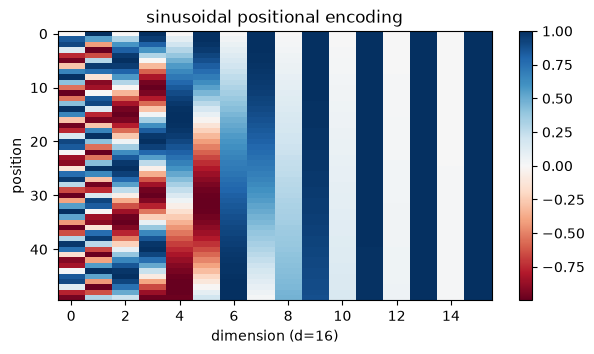

In [9]:
device = get_device()
P = positional_encoding(50, 16).to(device)

plt.figure(figsize=(7, 3.5))
plt.imshow(P.cpu(), cmap="RdBu", aspect="auto")
plt.xlabel("dimension (d=16)"); plt.ylabel("position"); plt.colorbar()
plt.title("sinusoidal positional encoding"); plt.show()

## 4. `nn.MultiheadAttention`으로 같은 계산
PyTorch에 이미 있음. 가중치를 1번과 같게(단위 행렬) 넣으면 같은 숫자가 나와야 함

In [14]:
device = get_device()

mha = nn.MultiheadAttention(embed_dim=2, num_heads=1, bias=False, batch_first=True)
with torch.no_grad():
    mha.in_proj_weight.copy_(torch.cat([torch.eye(2)] * 3))   # W_Q, W_K, W_V를 세로로 이어 붙인 것
    mha.out_proj.weight.copy_(torch.eye(2))                   # 마지막 출력 변환 W_O

X = torch.tensor([[emb["baseball"], emb["bat"]]]).to(device)  # (배치 1, 단어 2, 차원 2)
mha = mha.to(device)
out, attn = mha(X, X, X)                                      # 셀프 어텐션: Q, K, V 모두 X에서
print("가중치\n", attn[0])
print("출력\n", out[0])

가중치
 tensor([[0.50, 0.50],
        [0.33, 0.67]], device='cuda:0', grad_fn=<SelectBackward0>)
출력
 tensor([[1.00, 0.50],
        [1.00, 0.67]], device='cuda:0', grad_fn=<SelectBackward0>)


멀티헤드: 차원을 헤드 수로 나눠서 여러 관점으로 동시에 어텐션. 모양 확인

In [15]:
device = get_device()
    
mha4 = nn.MultiheadAttention(embed_dim=8, num_heads=4, batch_first=True)    # 헤드마다 8/4 = 2차원
x = torch.randn(3, 5, 8).to(device)                                          # 배치 3, 단어 5, 차원 8
mha4 = mha4.to(device)
out, attn = mha4(x, x, x, average_attn_weights=False)
print("입력", tuple(x.shape), "→ 출력", tuple(out.shape))
print("어텐션 가중치", tuple(attn.shape), "= (배치, 헤드, 단어, 단어)")
for name, p in mha4.named_parameters():
    p = p.to(device)
    print(f"  {name:16s} {tuple(p.shape)}")

입력 (3, 5, 8) → 출력 (3, 5, 8)
어텐션 가중치 (3, 4, 5, 5) = (배치, 헤드, 단어, 단어)
  in_proj_weight   (24, 8)
  in_proj_bias     (24,)
  out_proj.weight  (8, 8)
  out_proj.bias    (8,)


- 출력 모양은 입력과 같음 (3, 5, 8) → 층을 여러 개 쌓기 쉬움
- `in_proj_weight` (24, 8) = $W_Q, W_K, W_V$ 세 개 (8×8)를 이어 붙인 것, `out_proj` = $W_O$
- 파라미터 수는 문장 길이(5)와 상관없음

## 5. 학습: bat → 배트? 박쥐?
1번은 W를 직접 정했지만, 실제로는 **학습으로 W_Q, W_K, W_V를 찾음**

- 문장: 단어 5개. bat 1개 + 문맥 단어 1개 + 나머지는 의미 없는 단어(I, saw, a, the). 위치는 랜덤
- 문맥 단어: baseball, glove, pitcher → **배트(0)** / cave, night, wing → **박쥐(1)**
- 모델: 임베딩 → 셀프 어텐션 1개 → **bat 자리의 출력**만 꺼내서 → Linear(8 → 2)

In [17]:
import random

random.seed(0)

device = get_device()

vocab = ["baseball", "glove", "pitcher", "cave", "night", "wing", "bat", "I", "saw", "a", "the"]
w2i = {w: i for i, w in enumerate(vocab)}
sport, animal, filler = ["baseball", "glove", "pitcher"], ["cave", "night", "wing"], ["I", "saw", "a", "the"]
L = 5   # 문장 길이

def make_data(n):
    X, P, Y = [], [], []

    for _ in range(n):
        y = random.randint(0, 1)                                # 0: 배트, 1: 박쥐
        words = random.choices(filler, k=L)  # filLer; not filter.
        p_bat, p_ctx = random.sample(range(L), 2)               # bat과 문맥 단어 위치 (랜덤)
        words[p_bat] = "bat"
        words[p_ctx] = random.choice(sport if y == 0 else animal)
        # print(words, p_bat, p_ctx, y)  # 디버깅용
        X.append([w2i[w] for w in words]); P.append(p_bat); Y.append(y)
    return torch.tensor(X), torch.tensor(P), torch.tensor(Y)

X_train, P_train, y_train = make_data(2000)
X_test, P_test, y_test = make_data(500)
X_train, P_train, y_train = X_train.to(device), P_train.to(device), y_train.to(device)
X_test, P_test, y_test = X_test.to(device), P_test.to(device), y_test.to(device)
print("예시:", [vocab[i] for i in X_train[0]], "→", ["배트", "박쥐"][y_train[0]])


예시: ['the', 'saw', 'bat', 'night', 'saw'] → 박쥐


In [35]:
device = get_device()

class BatAttention(nn.Module):
    def __init__(self, d=8):
        super().__init__()
        self.to(device)
        self.emb = nn.Embedding(len(vocab), d)          # 단어 번호 → 벡터 (학습)
        self.W_Q = nn.Linear(d, d, bias=False)
        self.W_K = nn.Linear(d, d, bias=False)
        self.W_V = nn.Linear(d, d, bias=False)
        self.fc = nn.Linear(d, 2)
    def forward(self, x, p_bat):
        x, p_bat = x.to(device), p_bat.to(device)
        
        X = self.emb(x)                                  # (배치, 5, 8)
        Q, K, V = self.W_Q(X), self.W_K(X), self.W_V(X)
        S = Q @ K.transpose(1, 2) / math.sqrt(K.shape[-1])   # (배치, 5, 5)
        A = torch.softmax(S, dim=-1)
        O = A @ V                                        # (배치, 5, 8)
        o_bat = O[torch.arange(len(x)), p_bat]           # bat 자리의 출력만 (배치, 8)

        # print(o_bat.shape)  # 디버깅용
        return self.fc(o_bat), A

model = BatAttention()
model = model.to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(1, 101):
    logits, _ = model(X_train, P_train)  # RuntimeError: Expected all tensors to be on the same device, but got index is on cuda:0, different from other tensors on cpu (when checking argument in method wrapper_CUDA__index_select)

    P_test = P_test.to(device)
    X_test = X_test.to(device)
    y_test = y_test.to(device)
    X_train = X_train.to(device)
    P_train = P_train.to(device)
    y_train = y_train.to(device)

    loss = loss_fn(logits, y_train)
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    if epoch in (1, 10, 20, 50, 100):
        with torch.no_grad():
            logits, _ = model(X_test.to(device), P_test.to(device))
            acc = (logits.argmax(1) == y_test).float().mean().item()

            print(f"Test accuracy at epoch {epoch}: {acc:.3f}")
            # print("Test predictions:", logits.argmax(1))
            # print("Test logits:", logits)
            # print("Test attention matrix:", _)
            # print("Test positions:", P_test)
            # print("Test labels:", y_test)
            # print("Test input:", X_test)
            # print("Test batch positions:", P_test)
            # print("Test batch outputs:", _[torch.arange(len(X_test)), P_test])
            # print("Test batch attention matrix:", _[torch.arange(len(X_test)), P_test][:, None])
            print("Test batch attention matrix shape:", _[torch.arange(len(X_test)), P_test][:, None].shape)
            print()
        print(f"epoch {epoch:3d} | loss {loss.item():.4f} | test 정확도 {acc:.3f}")


Test accuracy at epoch 1: 0.522
Test batch attention matrix shape: torch.Size([500, 1, 5])

epoch   1 | loss 0.7054 | test 정확도 0.522
Test accuracy at epoch 10: 0.720
Test batch attention matrix shape: torch.Size([500, 1, 5])

epoch  10 | loss 0.6203 | test 정확도 0.720
Test accuracy at epoch 20: 0.904
Test batch attention matrix shape: torch.Size([500, 1, 5])

epoch  20 | loss 0.3265 | test 정확도 0.904
Test accuracy at epoch 50: 1.000
Test batch attention matrix shape: torch.Size([500, 1, 5])

epoch  50 | loss 0.0061 | test 정확도 1.000
Test accuracy at epoch 100: 1.000
Test batch attention matrix shape: torch.Size([500, 1, 5])

epoch 100 | loss 0.0003 | test 정확도 1.000


어텐션 맵: 학습된 모델이 **bat 자리에서 어느 단어를 보는지** 확인

I saw a baseball bat → bat 행 가중치 [0.0, 0.0, 0.0, 1.0, 0.0]
the bat saw a cave → bat 행 가중치 [0.13, 0.0, 0.51, 0.0, 0.36]
glove a bat the I → bat 행 가중치 [0.99, 0.0, 0.0, 0.01, 0.0]


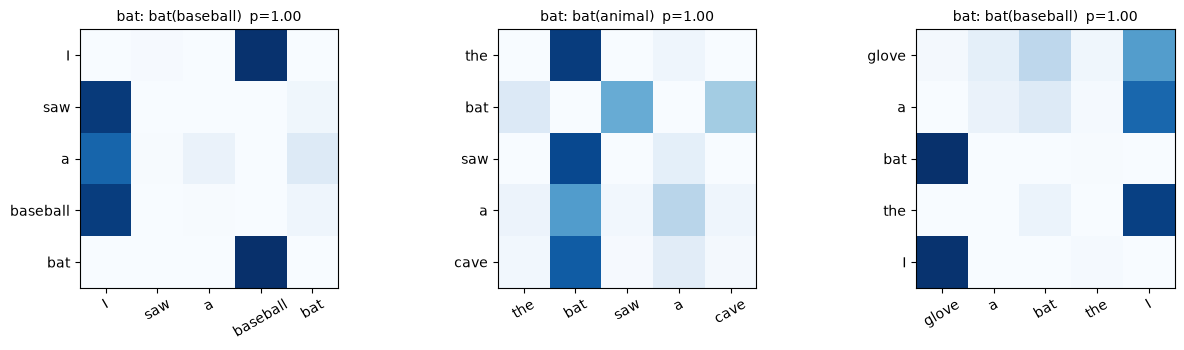

In [36]:
device = get_device()

examples = [["I", "saw", "a", "baseball", "bat"],
            ["the", "bat", "saw", "a", "cave"],
            ["glove", "a", "bat", "the", "I"]]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, words in zip(axes, examples):
    x = torch.tensor([[w2i[w] for w in words]])
    x = x.to(device)
    p = torch.tensor([words.index("bat")])
    p = p.to(device)
    with torch.no_grad():
        logits, A = model(x, p)
    prob = torch.softmax(logits, 1)[0]
    A = A.to("cpu")  # Move attention matrix to CPU for visualization
    ax.imshow(A[0], cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(words))); ax.set_xticklabels(words, rotation=30)
    ax.set_yticks(range(len(words))); ax.set_yticklabels(words)
    ax.set_title(f"bat: {'bat(baseball)' if prob[0] > 0.5 else 'bat(animal)'}  p={prob.max():.2f}", fontsize=10)
    print(" ".join(words), "→ bat 행 가중치", [round(v, 2) for v in A[0, p.item()].tolist()])
plt.tight_layout(); plt.show()


- bat 행을 보면 문맥 단어(baseball, cave, glove)에 가중치가 **0.88 ~ 0.99**로 몰림 → 위치가 어디든 직접 찾아감
- 사람이 "문맥 단어를 봐라"라고 알려 준 적 없음. 정답만 보고 W_Q, W_K를 학습해서 스스로 찾음
- RNN 실습1의 박쥐 실험은 W_hh(기억)로 해결, 여기서는 어텐션으로 해결

## 6. 마스크: 미래 가리기
문장을 만들어 내는 모델(GPT 같은 디코더)은 **앞 단어만 보고 다음 단어를 맞혀야 함** → 뒤쪽 단어를 가림

In [39]:
device = get_device()
    
sent = ["baseball", "bat", "cave"]
X = torch.tensor([emb[w] for w in sent])
X = X.to(device)

mask = torch.triu(torch.ones(3, 3, dtype=torch.bool), diagonal=1)   # 대각선 위쪽 = 미래
mask = mask.to(device)
print("마스크 (True = 가림)\n", mask)
A, O = self_attention(X, W_Q, W_K, W_V, mask=mask, show=False)  # RuntimeError: Expected all tensors to be on the same device, but got mat2 is on cpu, different from other tensors on cuda:0 (when checking argument in method wrapper_CUDA_mm)

print("마스크 있음\n", A)
A, O = self_attention(X, W_Q, W_K, W_V, show=False)
A = A.to("cpu")  # Move attention matrix to CPU for visualization
print("마스크 없음\n", A)

마스크 (True = 가림)
 tensor([[False,  True,  True],
        [False, False,  True],
        [False, False, False]], device='cuda:0')
마스크 있음
 tensor([[1.00, 0.00, 0.00],
        [0.33, 0.67, 0.00],
        [0.20, 0.40, 0.40]], device='cuda:0')
마스크 없음
 tensor([[0.40, 0.40, 0.20],
        [0.25, 0.50, 0.25],
        [0.20, 0.40, 0.40]])


- 마스크가 있으면 대각선 위쪽이 모두 0: 1번째 단어는 자기만, 2번째는 1~2번째만 봄
- 마스크가 없으면(BERT 같은 인코더) 앞뒤를 모두 봄

## 7. 문제: 코드를 직접 고쳐 보기
1. `self_attention`에서 `/ math.sqrt(d_k)`를 지우고 1번을 다시 실행하기. bat 행 가중치는 어떻게 바뀔까?
2. 1번에서 `W_V = torch.tensor([[0., 1.], [1., 0.]])` (두 칸 바꾸기)로 바꾸면 A와 O 중 무엇이 바뀔까? 이유는?
3. `d_k`가 클 때 나누기가 필요한 이유 확인: `torch.manual_seed(1)` 후 `q = torch.randn(64)`, `K = torch.randn(10, 64)`로 점수 `K @ q`를 만들고, 나누기 있음/없음의 softmax 최댓값을 비교하기.
4. 5번 학습에서 문장 길이 `L = 10`으로 늘리면 정확도는? RNN이었다면 어땠을까?
5. 5번 학습에서 문맥 단어를 추가하기: `sport`에 "stadium", `animal`에 "bird". 어디를 고쳐야 할까?
6. 5번 모델의 `forward`에 6번의 마스크(미래 가리기)를 넣고 다시 학습하기. 정확도가 얼마나 떨어질까? 이유는?
7. (도전) 5번 모델의 W_Q, W_K, W_V 부분을 `nn.MultiheadAttention(d, num_heads=2, batch_first=True)`로 바꾸기.

<details><summary>정답 보기</summary>

1. 점수 [1, 2] 그대로 softmax → [0.27, 0.73]. 나누지 않으면 큰 점수 쪽으로 더 쏠림 (0.67 → 0.73).
2. A는 그대로, O만 바뀜 ([1.00, 0.67] → [0.67, 1.00]). A는 Q·K로만 정해지고 V는 "무엇을 전달할지"만 정함.
3. `s = K @ q` 후 `torch.softmax(s, 0).max()`와 `torch.softmax(s / 8, 0).max()`. 실행 결과: 나누기 없음 1.00, 있음 0.44. 차원이 64개면 점수가 ±15 정도로 커져서 softmax가 한 칸에 거의 1을 몰아줌. √64 = 8로 나누면 고르게 퍼짐. 한 칸에 몰리면 나머지 칸의 기울기가 거의 0이 되어 학습이 어려움.
4. 실행 결과 예: 10단어도 20 에폭에 정확도 0.998, 50 에폭부터 1.000. 어텐션은 거리와 상관없이 한 번에 연결됨. RNN은 문맥 단어가 멀수록 기억이 흐려질 수 있음.
5. `vocab`에 두 단어 추가 (Embedding 크기가 `len(vocab)`이라 자동으로 맞춰짐), `sport`, `animal` 리스트에 추가하고 데이터 다시 만들기.
6. `S = S.masked_fill(torch.triu(torch.ones(L, L, dtype=torch.bool), 1), float("-inf"))`를 softmax 앞에 추가. 실행 결과 예: 정확도 약 0.75. 문맥 단어가 bat **뒤에** 있는 경우(약 절반)는 볼 수 없어서 찍어야 함 → 그 절반의 절반(약 25%)을 틀림.
7. `self.attn = nn.MultiheadAttention(d, 2, batch_first=True)`, forward에서 `O, A = self.attn(X, X, X)`. 정확도 1.000. A는 두 헤드의 평균으로 나옴.
</details>